In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
df = pd.read_csv("csv/cell_samples.csv")
df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,2
695,841769,2,1,1,1,2,1,1,1,1,2
696,888820,5,10,10,3,7,3,8,10,2,4
697,897471,4,8,6,4,3,4,10,6,1,4


In [4]:
df = df[pd.to_numeric(df['BareNuc'], errors='coerce').notnull()]
df['BareNuc'] = df['BareNuc'].astype(int)
df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int64
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

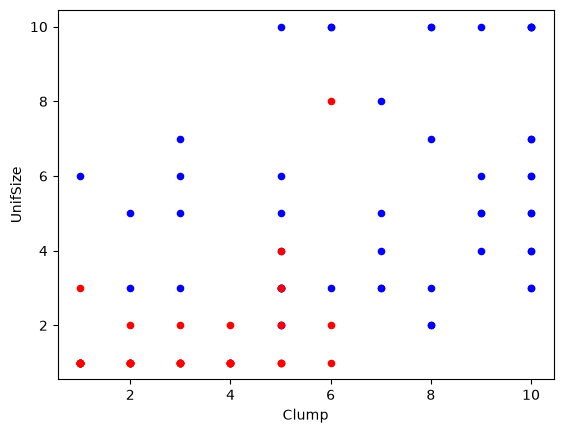

In [5]:
ax = df[df['Class'] == 4][0:50].plot(kind='scatter',x='Clump',y='UnifSize',color='b');
df[df['Class'] == 2][0:50].plot(kind='scatter',x='Clump',y='UnifSize',color='r',ax=ax);
plt.show()

In [6]:
x = df.drop(columns=["Class","ID"])
y = df['Class'].astype('int')
x = np.asarray(x)
y = np.asarray(y)

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4)

In [14]:
from sklearn import svm
from sklearn.metrics import jaccard_score, f1_score, accuracy_score
for kernel in ['rbf','poly','linear','sigmoid']:
    try:
        clf = svm.SVC(kernel=kernel).fit(x_train, y_train)
        y_pre = clf.predict(x_test)
        ja = jaccard_score(y_test, y_pre, pos_label=2)
        f1 = f1_score(y_test, y_pre, average='weighted')
        acc = accuracy_score(y_test, y_pre)
        print("kernel: ",kernel,"\njaccard score: ",ja,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n")
    except Exception as e:
        print("Error: ",e)

kernel:  rbf 
jaccard score:  0.9444444444444444 
f1 score:  0.9639038982104676 
accuracy score:  0.9635036496350365 

kernel:  poly 
jaccard score:  0.9555555555555556 
f1 score:  0.9710669934861801 
accuracy score:  0.9708029197080292 

kernel:  linear 
jaccard score:  0.9444444444444444 
f1 score:  0.9639038982104676 
accuracy score:  0.9635036496350365 

kernel:  sigmoid 
jaccard score:  0.39416058394160586 
f1 score:  0.37146023617533536 
accuracy score:  0.39416058394160586 



In [15]:
clf = svm.SVC(kernel='rbf').fit(x_train, y_train)
y_pre = clf.predict(x_test)

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

In [17]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

              precision    recall  f1-score   support

           2       1.00      0.94      0.97        90
           4       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137

Confusion matrix, without normalization
[[85  5]
 [ 0 47]]


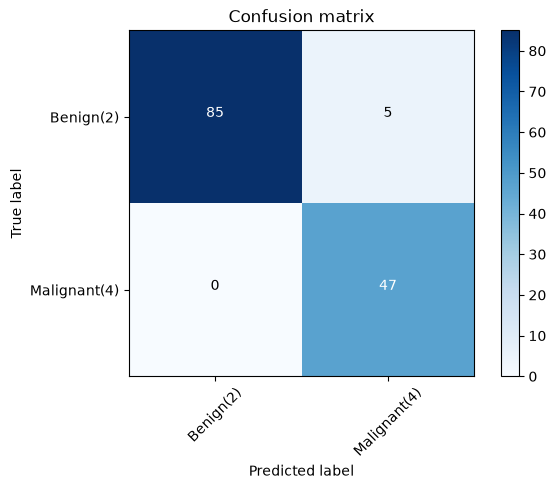

In [18]:
cnf_matrix = confusion_matrix(y_test, y_pre, labels=[2,4])
np.set_printoptions(precision=2)

print (classification_report(y_test, y_pre))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['Benign(2)','Malignant(4)'],normalize= False,  title='Confusion matrix')